In [1]:
import pandas as pd

url = 'https://raw.githubusercontent.com/montajebii/tgju-asset-history/main/data/dollar_price_history.csv'

df_usd = pd.read_csv(url)

print(df_usd.shape)
display(df_usd.head())

(4012, 6)


,Date,Persian_Date,Open,Low,High,Close
0,2011/11/26,1390/09/05,13700,13700,13700,13700
1,2011/11/27,1390/09/06,13440,13440,13440,13440
2,2011/11/28,1390/09/07,13350,13350,13350,13350
3,2011/11/30,1390/09/09,13500,13500,13500,13500
4,2011/12/03,1390/09/12,13610,13610,13610,13610


In [2]:
usd_quality = pd.DataFrame({
    'column': df_usd.columns,
    'missing_values': df_usd.isna().sum().values,
    'data_type': df_usd.dtypes.astype(str).values,
    'unique_values': df_usd.nunique().values
})

display(usd_quality)

,column,missing_values,data_type,unique_values
0,Date,0,object,4012
1,Persian_Date,0,object,4012
2,Open,0,int64,3188
3,Low,0,int64,2960
4,High,0,int64,2952
5,Close,0,int64,3129


In [3]:
print("Duplicate dates:", df_usd['Date'].duplicated().sum())

Duplicate dates: 0


In [4]:
print("Low > High:", (df_usd['Low'] > df_usd['High']).sum())

print("Open outside range:", (
    (df_usd['Open'] < df_usd['Low']) |
    (df_usd['Open'] > df_usd['High'])
).sum())

print("Close outside range:", (
    (df_usd['Close'] < df_usd['Low']) |
    (df_usd['Close'] > df_usd['High'])
).sum())

print("Zero or negative prices:", (
    (df_usd[['Open', 'Low', 'High', 'Close']] <= 0)
    .any(axis=1)
).sum())

Low > High: 0
Open outside range: 0
Close outside range: 0
Zero or negative prices: 0


In [6]:
df_usd['Date'] = pd.to_datetime(
    df_usd['Date'],
    format='%Y/%m/%d'
)

print(df_usd.dtypes)

print("Start date:", df_usd['Date'].min())
print("End date:", df_usd['Date'].max())

Date            datetime64[ns]
Persian_Date            object
Open                     int64
Low                      int64
High                     int64
Close                    int64
dtype: object
Start date: 2011-11-26 00:00:00
End date: 2026-11-24 00:00:00


In [7]:
df_usd['Year'] = df_usd['Date'].dt.year
df_usd['Month'] = df_usd['Date'].dt.month

df_usd['Year_Month'] = (
    df_usd['Date'].dt.to_period('M').astype(str)
)

display(df_usd.head())

,Date,Persian_Date,Open,Low,High,Close,Year,Month,Year_Month
0,2011-11-26,1390/09/05,13700,13700,13700,13700,2011,11,2011-11
1,2011-11-27,1390/09/06,13440,13440,13440,13440,2011,11,2011-11
2,2011-11-28,1390/09/07,13350,13350,13350,13350,2011,11,2011-11
3,2011-11-30,1390/09/09,13500,13500,13500,13500,2011,11,2011-11
4,2011-12-03,1390/09/12,13610,13610,13610,13610,2011,12,2011-12


In [8]:
date_range = pd.date_range(
    start=df_usd['Date'].min(),
    end=df_usd['Date'].max(),
    freq='D'
)

missing_dates = date_range.difference(df_usd['Date'])

print("Total calendar days:", len(date_range))
print("Available records:", len(df_usd))
print("Missing calendar days:", len(missing_dates))

print("\nFirst 20 missing dates:")
print(missing_dates[:20])

Total calendar days: 5478
Available records: 4012
Missing calendar days: 1466

First 20 missing dates:
DatetimeIndex(['2011-11-29', '2011-12-01', '2011-12-02', '2011-12-04',
               '2011-12-05', '2011-12-06', '2011-12-08', '2011-12-09',
               '2011-12-15', '2011-12-16', '2011-12-22', '2011-12-23',
               '2011-12-29', '2011-12-30', '2012-01-05', '2012-01-06',
               '2012-01-12', '2012-01-13', '2012-01-14', '2012-01-19'],
              dtype='datetime64[ns]', freq=None)


In [9]:
missing_by_weekday = pd.Series(
    missing_dates.day_name()
).value_counts()

print("Missing dates by weekday:")
display(missing_by_weekday)

Missing dates by weekday:


,count
Friday,674
Thursday,440
Sunday,78
Saturday,76
Tuesday,72
Monday,68
Wednesday,58


In [10]:
annual_records = (
    df_usd.groupby('Year')
    .agg(
        records=('Date', 'count'),
        first_date=('Date', 'min'),
        last_date=('Date', 'max')
    )
    .reset_index()
)

annual_records['records'] = annual_records['records'].astype(int)

display(annual_records)

,Year,records,first_date,last_date
0,2011,22,2011-11-26,2011-12-31
1,2012,245,2012-01-01,2012-12-31
2,2013,234,2013-01-01,2013-12-30
3,2014,284,2014-01-01,2014-12-30
4,2015,249,2015-01-01,2015-12-30
5,2016,239,2016-01-02,2016-12-31
6,2017,238,2017-01-01,2017-12-31
7,2018,274,2018-01-01,2018-12-31
8,2019,283,2019-01-01,2019-12-31
9,2020,286,2020-01-01,2020-12-30


In [11]:
monthly_records = (
    df_usd[
        (df_usd['Year'] >= 2021) &
        (df_usd['Year'] <= 2025)
    ]
    .groupby('Year_Month')
    .agg(
        records=('Date', 'count'),
        first_date=('Date', 'min'),
        last_date=('Date', 'max')
    )
    .reset_index()
)

display(monthly_records)

,Year_Month,records,first_date,last_date
0,2021-01,25,2021-01-02,2021-01-31
1,2021-02,22,2021-02-01,2021-02-28
2,2021-03,20,2021-03-01,2021-03-31
3,2021-04,24,2021-04-03,2021-04-29
4,2021-05,24,2021-05-01,2021-05-31
5,2021-06,24,2021-06-01,2021-06-30
6,2021-07,23,2021-07-01,2021-07-31
7,2021-08,24,2021-08-01,2021-08-31
8,2021-09,25,2021-09-01,2021-09-30
9,2021-10,22,2021-10-02,2021-10-31


In [13]:
june_2025_dates = pd.date_range(
    start='2025-06-01',
    end='2025-06-30',
    freq='D'
)

june_2025_missing = june_2025_dates.difference(
    df_usd.loc[
        df_usd['Year_Month'] == '2025-06',
        'Date'
    ]
)

print("Missing dates in June 2025:")
print(june_2025_missing)

print("\nMissing dates by weekday:")
display(
    pd.Series(june_2025_missing.day_name())
    .value_counts()
)

Missing dates in June 2025:
DatetimeIndex(['2025-06-03', '2025-06-04', '2025-06-05', '2025-06-12',
               '2025-06-13', '2025-06-14', '2025-06-15', '2025-06-16',
               '2025-06-17', '2025-06-18', '2025-06-19', '2025-06-20',
               '2025-06-21', '2025-06-22', '2025-06-23', '2025-06-26'],
              dtype='datetime64[ns]', freq=None)

Missing dates by weekday:


,count
Thursday,4
Tuesday,2
Wednesday,2
Friday,2
Saturday,2
Sunday,2
Monday,2


In [14]:
df_usd_analysis = df_usd[
    (df_usd['Year'] >= 2021) &
    (df_usd['Year'] <= 2025)
].copy()

print("Dataset shape:", df_usd_analysis.shape)

display(df_usd_analysis.head())
display(df_usd_analysis.tail())

Dataset shape: (1392, 9)


,Date,Persian_Date,Open,Low,High,Close,Year,Month,Year_Month
2354,2021-01-02,1399/10/13,255840,255440,257550,257140,2021,1,2021-01
2355,2021-01-03,1399/10/14,257790,257240,259050,258980,2021,1,2021-01
2356,2021-01-04,1399/10/15,259030,258440,261050,260980,2021,1,2021-01
2357,2021-01-05,1399/10/16,260620,257540,260650,258530,2021,1,2021-01
2358,2021-01-06,1399/10/17,256550,254240,256550,254850,2021,1,2021-01


,Date,Persian_Date,Open,Low,High,Close,Year,Month,Year_Month
3741,2025-12-27,1404/10/06,1344150,1344100,1388500,1388300,2025,12,2025-12
3742,2025-12-28,1404/10/07,1394950,1394600,1445000,1419100,2025,12,2025-12
3743,2025-12-29,1404/10/08,1417500,1375800,1417600,1377200,2025,12,2025-12
3744,2025-12-30,1404/10/09,1369850,1369800,1397000,1395700,2025,12,2025-12
3745,2025-12-31,1404/10/10,1397500,1355400,1397500,1355650,2025,12,2025-12


In [15]:
monthly_usd = (
    df_usd_analysis
    .groupby('Year_Month')
    .agg(
        mean_close=('Close', 'mean'),
        median_close=('Close', 'median'),
        min_close=('Close', 'min'),
        max_close=('Close', 'max'),
        records=('Close', 'count')
    )
    .reset_index()
)

monthly_usd['mean_close_toman'] = (
    monthly_usd['mean_close'] / 10
)

monthly_usd = monthly_usd.round(2)

display(monthly_usd.head(12))

,Year_Month,mean_close,median_close,min_close,max_close,records,mean_close_toman
0,2021-01,241716.00,239650.0,219830,260980,25,24171.60
1,2021-02,249503.18,250585.0,237470,261450,22,24950.32
2,2021-03,249473.35,248750.0,239630,257960,20,24947.34
3,2021-04,243296.67,243250.0,232310,252450,24,24329.67
4,2021-05,226090.83,227355.0,206480,238570,24,22609.08
5,2021-06,242269.17,241600.0,234160,253990,24,24226.92
6,2021-07,249391.74,249800.0,244670,256140,23,24939.17
7,2021-08,267946.25,269080.0,255190,278990,24,26794.62
8,2021-09,275528.80,274510.0,270670,284710,25,27552.88
9,2021-10,275357.73,275325.0,270700,281380,22,27535.77


In [16]:
print("Number of months:", len(monthly_usd))

print("\nMonthly record count:")
display(
    monthly_usd[
        ['Year_Month', 'records']
    ].to_string(index=False)
)

print("\nSummary of monthly records:")
display(monthly_usd['records'].describe())

Number of months: 60

Monthly record count:


'Year_Month  records\n   2021-01       25\n   2021-02       22\n   2021-03       20\n   2021-04       24\n   2021-05       24\n   2021-06       24\n   2021-07       23\n   2021-08       24\n   2021-09       25\n   2021-10       22\n   2021-11       26\n   2021-12       25\n   2022-01       25\n   2022-02       21\n   2022-03       21\n   2022-04       23\n   2022-05       22\n   2022-06       19\n   2022-07       19\n   2022-08       21\n   2022-09       22\n   2022-10       26\n   2022-11       25\n   2022-12       24\n   2023-01       23\n   2023-02       17\n   2023-03       17\n   2023-04       20\n   2023-05       26\n   2023-06       22\n   2023-07       26\n   2023-08       26\n   2023-09       21\n   2023-10       25\n   2023-11       25\n   2023-12       26\n   2024-01       26\n   2024-02       20\n   2024-03       21\n   2024-04       24\n   2024-05       25\n   2024-06       22\n   2024-07       25\n   2024-08       24\n   2024-09       22\n   2024-10       26\n   2024-11  


Summary of monthly records:


,records
count,60.000000
mean,23.200000
std,2.666808
min,14.000000
25%,22.000000
50%,24.000000
75%,25.000000
max,27.000000


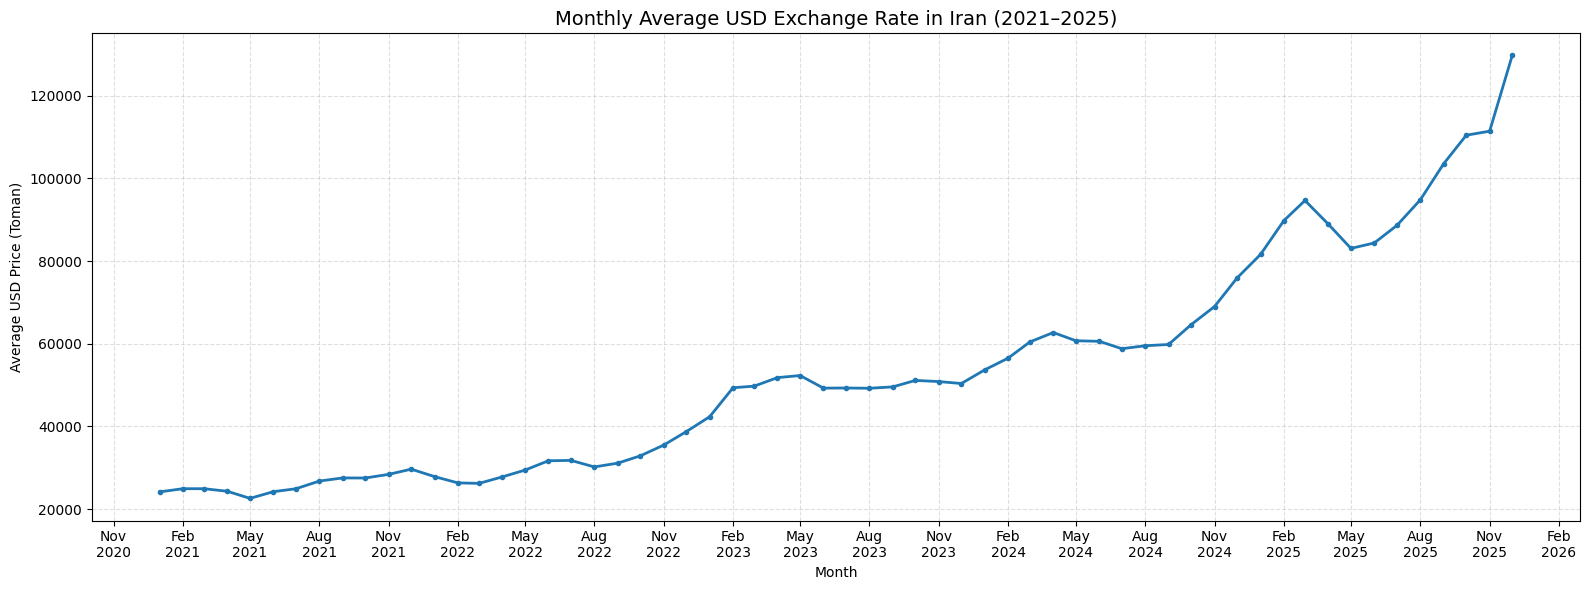

In [17]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

monthly_usd['Gregorian_Date'] = pd.to_datetime(
    monthly_usd['Year_Month'],
    format='%Y-%m'
)

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_usd['Gregorian_Date'],
    monthly_usd['mean_close_toman'],
    linewidth=2,
    marker='o',
    markersize=3
)

plt.title(
    'Monthly Average USD Exchange Rate in Iran (2021–2025)',
    fontsize=14
)

plt.xlabel('Month')
plt.ylabel('Average USD Price (Toman)')

plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter('%b\n%Y')
)

plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


In [18]:
monthly_usd['monthly_change_pct'] = (
    monthly_usd['mean_close_toman'].pct_change() * 100
)

monthly_usd['monthly_change_toman'] = (
    monthly_usd['mean_close_toman'].diff()
)

display(
    monthly_usd[
        [
            'Year_Month',
            'mean_close_toman',
            'monthly_change_toman',
            'monthly_change_pct'
        ]
    ].head(15).round(2)
)

,Year_Month,mean_close_toman,monthly_change_toman,monthly_change_pct
0,2021-01,24171.60,NaN,NaN
1,2021-02,24950.32,778.72,3.22
2,2021-03,24947.34,-2.98,-0.01
3,2021-04,24329.67,-617.67,-2.48
4,2021-05,22609.08,-1720.59,-7.07
5,2021-06,24226.92,1617.84,7.16
6,2021-07,24939.17,712.25,2.94
7,2021-08,26794.62,1855.45,7.44
8,2021-09,27552.88,758.26,2.83
9,2021-10,27535.77,-17.11,-0.06


In [19]:
# بیشترین افزایش ماهانه
max_increase = monthly_usd.loc[
    monthly_usd['monthly_change_pct'].idxmax()
]

# بیشترین کاهش ماهانه
max_decrease = monthly_usd.loc[
    monthly_usd['monthly_change_pct'].idxmin()
]

print("Highest Monthly Increase:")
display(max_increase)

print("\nHighest Monthly Decrease:")
display(max_decrease)

print("\nNumber of Increasing Months:")
print((monthly_usd['monthly_change_pct'] > 0).sum())

print("\nNumber of Decreasing Months:")
print((monthly_usd['monthly_change_pct'] < 0).sum())

print("\nNumber of Unchanged Months:")
print((monthly_usd['monthly_change_pct'] == 0).sum())

Highest Monthly Increase:


,25
Year_Month,2023-02
mean_close,493640.59
median_close,472170.0
min_close,442370
max_close,584930
records,17
mean_close_toman,49364.06
Gregorian_Date,2023-02-01 00:00:00
monthly_change_pct,16.535323
monthly_change_toman,7004.32



Highest Monthly Decrease:


,4
Year_Month,2021-05
mean_close,226090.83
median_close,227355.0
min_close,206480
max_close,238570
records,24
mean_close_toman,22609.08
Gregorian_Date,2021-05-01 00:00:00
monthly_change_pct,-7.071982
monthly_change_toman,-1720.59



Number of Increasing Months:
42

Number of Decreasing Months:
17

Number of Unchanged Months:
0


In [20]:
annual_usd = (
    monthly_usd
    .groupby(monthly_usd['Gregorian_Date'].dt.year)
    .agg(
        annual_mean_toman=('mean_close_toman', 'mean'),
        annual_median_toman=('mean_close_toman', 'median'),
        min_monthly_toman=('mean_close_toman', 'min'),
        max_monthly_toman=('mean_close_toman', 'max'),
        months=('Year_Month', 'count')
    )
    .reset_index()
    .rename(columns={'Gregorian_Date': 'Year'})
)

annual_usd['annual_change_pct'] = (
    annual_usd['annual_mean_toman'].pct_change() * 100
)

annual_usd = annual_usd.round(2)

display(annual_usd)

,Year,annual_mean_toman,annual_median_toman,min_monthly_toman,max_monthly_toman,months,annual_change_pct
0,2021,25845.58,24948.83,22609.08,29676.80,12,NaN
1,2022,30810.00,30671.73,26241.05,38753.42,12,19.21
2,2023,49617.50,49665.98,42359.74,52320.73,12,61.04
3,2024,61874.14,60523.24,53691.91,75947.12,12,24.70
4,2025,96751.74,92224.64,81608.54,129732.22,12,56.37


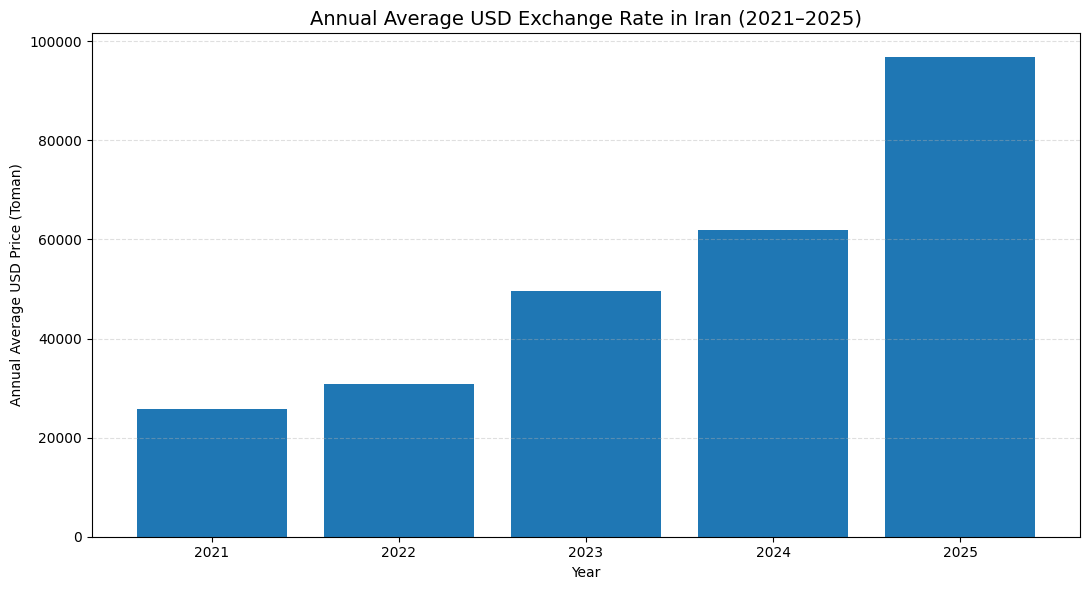

In [21]:
plt.figure(figsize=(11, 6))

plt.bar(
    annual_usd['Year'].astype(str),
    annual_usd['annual_mean_toman']
)

plt.title(
    'Annual Average USD Exchange Rate in Iran (2021–2025)',
    fontsize=14
)

plt.xlabel('Year')
plt.ylabel('Annual Average USD Price (Toman)')

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [22]:
base_usd = annual_usd.loc[
    annual_usd['Year'] == 2021,
    'annual_mean_toman'
].iloc[0]

annual_usd['cumulative_growth_pct'] = (
    (annual_usd['annual_mean_toman'] / base_usd) - 1
) * 100

annual_usd['growth_multiple'] = (
    annual_usd['annual_mean_toman'] / base_usd
)

display(
    annual_usd[
        [
            'Year',
            'annual_mean_toman',
            'cumulative_growth_pct',
            'growth_multiple'
        ]
    ].round(2)
)

,Year,annual_mean_toman,cumulative_growth_pct,growth_multiple
0,2021,25845.58,0.00,1.00
1,2022,30810.00,19.21,1.19
2,2023,49617.50,91.98,1.92
3,2024,61874.14,139.40,2.39
4,2025,96751.74,274.35,3.74


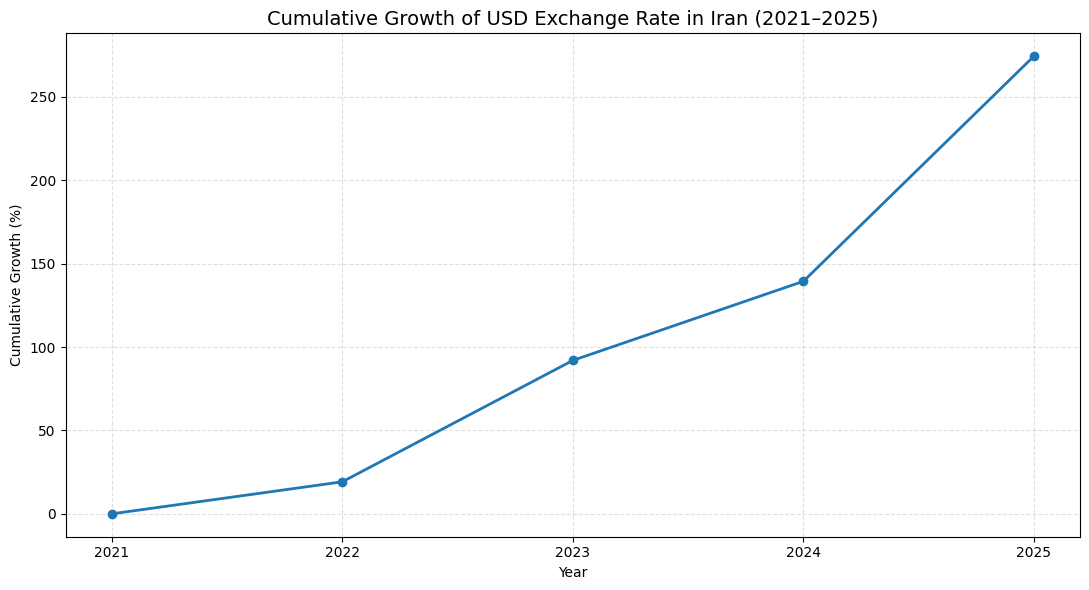

In [23]:
plt.figure(figsize=(11, 6))

plt.plot(
    annual_usd['Year'].astype(str),
    annual_usd['cumulative_growth_pct'],
    marker='o',
    linewidth=2
)

plt.title(
    'Cumulative Growth of USD Exchange Rate in Iran (2021–2025)',
    fontsize=14
)

plt.xlabel('Year')
plt.ylabel('Cumulative Growth (%)')

plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [24]:
print("Monthly Dataset Shape:", monthly_usd.shape)

print("\nMissing Values:")
display(monthly_usd.isnull().sum())

print("\nDuplicate Months:")
print(monthly_usd['Year_Month'].duplicated().sum())

print("\nDate Range:")
print(monthly_usd['Year_Month'].min(), "to", monthly_usd['Year_Month'].max())

print("\nMonthly Records:")
print("Minimum:", monthly_usd['records'].min())
print("Maximum:", monthly_usd['records'].max())
print("Average:", round(monthly_usd['records'].mean(), 2))

Monthly Dataset Shape: (60, 10)

Missing Values:


,0
Year_Month,0
mean_close,0
median_close,0
min_close,0
max_close,0
records,0
mean_close_toman,0
Gregorian_Date,0
monthly_change_pct,1
monthly_change_toman,1



Duplicate Months:
0

Date Range:
2021-01 to 2025-12

Monthly Records:
Minimum: 14
Maximum: 27
Average: 23.2


In [25]:
# ذخیره خروجی نهایی تحلیل دلار
monthly_usd.to_csv(
    'usd_analysis_final.csv',
    index=False,
    encoding='utf-8-sig'
)

print("USD analysis file saved successfully.")

print("File name: usd_analysis_final.csv")

print("Number of rows:", len(monthly_usd))

print("Number of columns:", len(monthly_usd.columns))


USD analysis file saved successfully.
File name: usd_analysis_final.csv
Number of rows: 60
Number of columns: 10


In [26]:
from google.colab import files
files.download('usd_analysis_final.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>